# Priorización de tareas con Qwen3.5-4B
## Entrenamiento con LoRA y DoRA

**Objetivo.** Adaptar un modelo para decidir la prioridad de una tarea según varios criterios y devolver una respuesta JSON verificable. Se conserva el enfoque de los notebooks del docente, con una tarea en español y la plantilla nativa de Qwen.

Este notebook muestra los datos, la configuración y los registros de la ejecución en Khipu. Reutiliza los resultados guardados para poder revisarse sin reservar otra GPU. La celda de reentrenamiento es opcional y está desactivada.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT / "results" / "COMPLETE.json").exists(), "Abra el notebook desde la carpeta del proyecto terminado."
metrics = json.loads((ROOT / "results" / "all_metrics.json").read_text(encoding="utf8"))
hardware = json.loads((ROOT / "results" / "hardware.json").read_text(encoding="utf8"))
summary = pd.read_csv(ROOT / "results" / "summary.csv")
names = {"base":"Base", "lora":"LoRA", "dora":"DoRA", "lora_replica":"LoRA, réplica"}
display(pd.DataFrame([{"GPU":hardware["gpu"], "Nodo":hardware["node"], "Job":hardware["job_id"], "PyTorch":hardware["torch"]}]))

,GPU,Nodo,Job,PyTorch
0,NVIDIA RTX A6000,ds001,58224,2.14.1+cu130


## 1. Problema y criterios

Cada ejemplo describe una tarea universitaria o de TI. El modelo debe considerar plazo, impacto, personas afectadas, dependencias, alternativas y riesgo activo. Las clases son **crítica, alta, media y baja**. Un bloqueo previo se informa, pero no reduce la prioridad.

El error más delicado es asignar una prioridad menor a una tarea crítica. Por ello, además de F1 macro, se calcula la recuperación de la clase crítica. El JSON contiene `prioridad`, `escalar`, `bloqueada` y `criterio`.

In [2]:
import sys
sys.path.insert(0, str(ROOT / "src"))
from dataset_generator import SYSTEM_INSTRUCTION
print(SYSTEM_INSTRUCTION)

Prioriza una tarea de gestión universitaria o soporte de TI.
Aplica estas reglas en orden:
1. critica: riesgo activo de seguridad física o exposición de datos; también interrupción total que afecta al menos a 50 personas y no tiene alternativa.
2. alta: plazo de hasta 8 horas y (impacto medio/alto o al menos 3 tareas dependientes); también impacto alto sin alternativa.
3. media: plazo de hasta 48 horas, impacto medio o alto, o al menos una tarea dependiente.
4. baja: los demás casos.
Un bloqueo previo no reduce la prioridad; solo se informa. Escalar si la prioridad es critica, o si es alta y el impacto es alto.
Indica el criterio decisivo: riesgo para seguridad/datos; impacto para interrupción crítica o impacto alto sin alternativa; plazo si activa una regla de plazo; dependencia si solo las dependencias activan media; planificacion para baja. En media, plazo precede a impacto y a dependencia.
Responde solo JSON con exactamente estas claves:
{"prioridad":"critica|alta|media|baja","esca

## 2. Datos y separación

Los 384 ejemplos son sintéticos y sus etiquetas siguen la política anterior. La separación se fija antes del entrenamiento: 256 ejemplos para entrenar, 48 para validar, 64 para probar y 16 casos con presión verbal, instrucciones contradictorias o cambios de tono. Las familias de tareas son distintas entre particiones.

El reparto equilibrado permite observar las cuatro clases con un conjunto pequeño; no representa su frecuencia real en una universidad.

In [3]:
audit = json.loads((ROOT / "data" / "checks.json").read_text(encoding="utf8"))
display(pd.DataFrame(audit["class_counts"]).T.rename_axis("Partición"))
rows = [json.loads(s) for s in (ROOT / "data" / "train.jsonl").read_text(encoding="utf8").splitlines()]
display(pd.DataFrame([{"Duplicados exactos":audit["exact_duplicates"], "Familias compartidas":audit["group_overlap"], "Campos ausentes":sum(any(k not in r for k in ["input","output","facts"]) for r in rows)}]))
display(Markdown("**Ejemplo de entrenamiento:** " + rows[0]["input"]))
print(rows[0]["output"])

,critica,alta,media,baja
Partición,,,,
train,64,64,64,64
validation,12,12,12,12
test,16,16,16,16
stress,4,4,4,4


,Duplicados exactos,Familias compartidas,Campos ausentes
0,0,0,0


**Ejemplo de entrenamiento:** Tarea: habilitar el sistema de pagos. Quedan 48 h para el vencimiento y hay 1 personas afectadas. La consecuencia es de impacto alto. Hay 3 tareas posteriores pendientes de esta. No hay riesgo activo para la seguridad física ni exposición de datos. No existe alternativa operativa. La tarea puede iniciarse; no tiene bloqueos previos. No hay interrupción total del servicio.

{"prioridad": "alta", "escalar": true, "bloqueada": false, "criterio": "impacto"}


Las comprobaciones no encontraron ejemplos exactos ni familias de tareas compartidas entre particiones. También se verifica que aumentar el impacto no reduzca la prioridad. La regla de referencia permanece fuera de las entradas del modelo; sus criterios sí aparecen en el prompt, porque forman parte de la tarea que debe resolver.

## 3. Configuración común

Los tres modelos usan la misma base Qwen3.5-4B cuantizada en NF4 de 4 bits. Los adaptadores mantienen rango 8 y alpha 16, con el mismo presupuesto de 32 actualizaciones y lote efectivo de 8 ejemplos. La semilla principal es 42; LoRA se repite con 43.

Cada adaptador parte de una carga independiente del modelo base. La pérdida se calcula únicamente sobre los tokens de la respuesta. La inferencia usa la plantilla oficial con `enable_thinking=False` y decodificación sin muestreo.

In [4]:
config = hardware["config"]
display(pd.DataFrame({"Parámetro":list(config), "Valor":[str(v) for v in config.values()]}))
revision = json.loads((ROOT / "model_revision.json").read_text(encoding="utf8"))
print("Revisión del modelo:", revision["revision"])
print("Las versiones exactas están en requirements-lock.txt.")

,Parámetro,Valor
0,model_name,Qwen/Qwen3.5-4B
1,model_path,/home/fabryzzio.meza/hackathon8_qwen35/model
2,seed,42
3,rank,8
4,alpha,16
5,dropout,0.05
6,learning_rate,0.0002
7,max_steps,32
8,gradient_accumulation_steps,8
9,batch_size,1


Revisión del modelo: 851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a
Las versiones exactas están en requirements-lock.txt.


## 4. Comparación con una tecnología más actual: DoRA

LoRA congela los pesos originales y aprende dos matrices pequeñas cuya multiplicación representa la actualización. Su escala es `alpha/r`. DoRA separa magnitud y dirección: usa una actualización de bajo rango para la dirección y añade un parámetro de magnitud. Esta diferencia puede aportar capacidad, pero también añade operaciones.

**DoRA es la tecnología posterior a LoRA elegida para la comparación solicitada. Se entrenó con PEFT, activando `use_dora=True` en `LoraConfig`; LoRA usa `False`. Los pesos obtenidos se incluyen en `adapters/dora/`.**

Se adaptan proyecciones de atención convencional y lineal de Qwen. El módulo visual no se utiliza, porque todas las entradas son texto. El código de carga y entrenamiento está en `src/experiment.py`.

Fuentes: [modelo Qwen](https://huggingface.co/Qwen/Qwen3.5-4B), [Transformers](https://huggingface.co/docs/transformers/en/model_doc/qwen3_5), [PEFT y DoRA](https://huggingface.co/docs/peft/en/package_reference/lora).

In [5]:
# Ejecutar únicamente dentro de una asignación GPU de Slurm.
TRAIN_NOW = False
if TRAIN_NOW:
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "src" / "experiment.py")], check=True)
else:
    print("Se muestran los registros de la ejecución terminada en Khipu.")
    print("Para una nueva ejecución: consulte README.md y envíe run.slurm con sbatch.")

Se muestran los registros de la ejecución terminada en Khipu.
Para una nueva ejecución: consulte README.md y envíe run.slurm con sbatch.


## 5. Entrenamiento observado

La tabla usa el tiempo medido alrededor del entrenamiento, sin incluir descarga ni espera en cola. La VRAM corresponde al máximo asignado por PyTorch al proceso; no incluye memoria de otros usuarios ni equivale al consumo total de la GPU.

,Método,Semilla,Pasos,Ejemplos vistos,Parámetros entrenables,Minutos,VRAM (GiB),Pérdida final
0,LoRA,42,32,256,4259840,2.762,3.235,0.022
1,DoRA,42,32,256,4591616,5.624,3.518,0.021
2,"LoRA, réplica",43,32,256,4259840,2.750,3.236,0.016


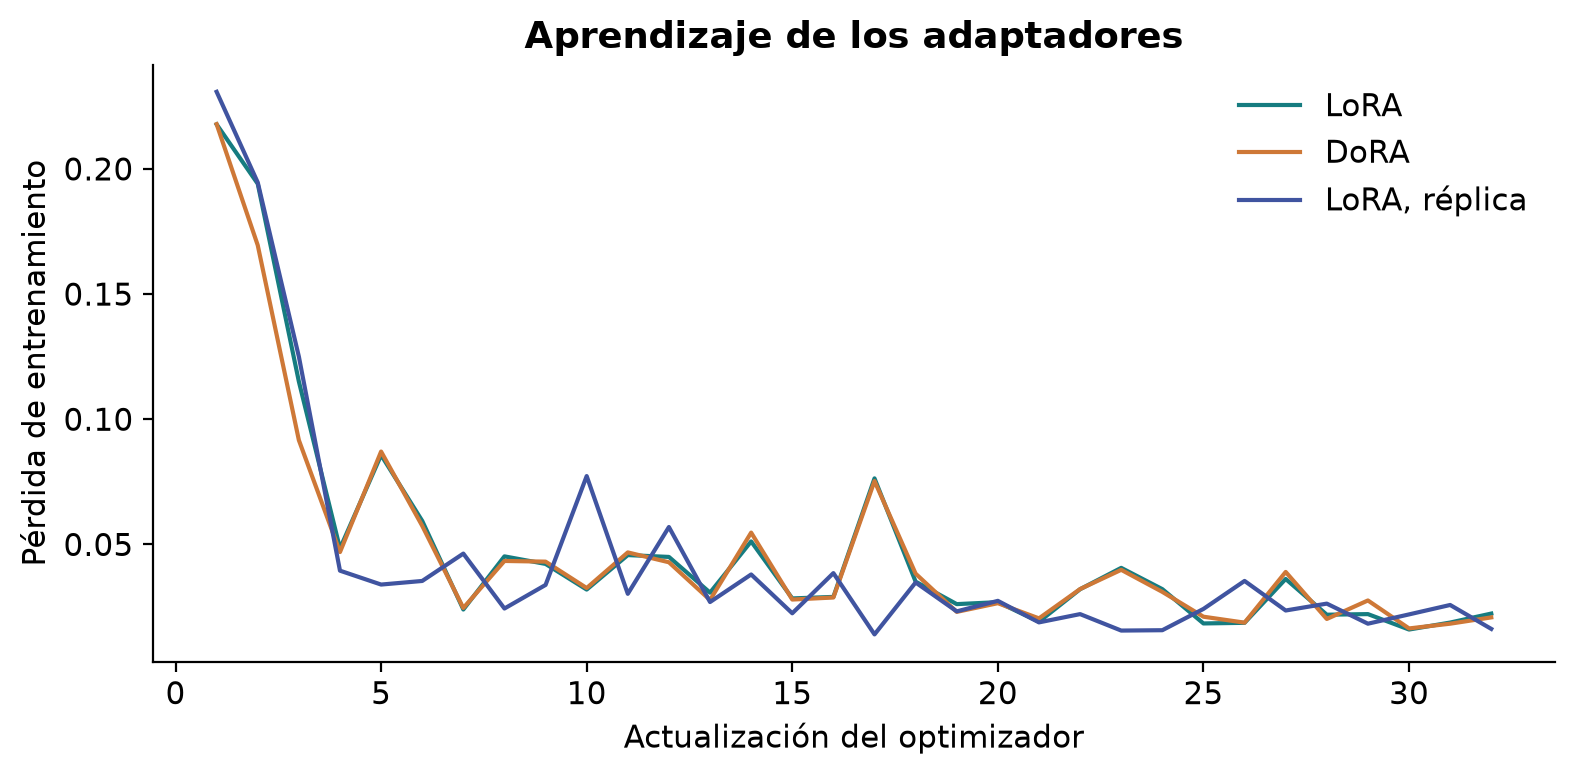

In [6]:
records=[]
for name, m in metrics.items():
    if m["training"]:
        t=m["training"]
        records.append({"Método":names[name], "Semilla":t["seed"], "Pasos":t["steps"], "Ejemplos vistos":t["examples_seen"], "Parámetros entrenables":t["trainable_parameters"], "Minutos":t["train_seconds"]/60, "VRAM (GiB)":t["train_peak_allocated_gb"], "Pérdida final":t["final_loss"]})
display(pd.DataFrame(records).round(3))
display(Image(filename=str(ROOT / "figures" / "entrenamiento.png")))

Una pérdida de entrenamiento menor indica mejor ajuste a las respuestas usadas para aprender. La comparación de generalización se realiza por separado en el notebook de evaluación; la curva de pérdida por sí sola no demuestra que un adaptador sea mejor.

## 6. Reproducibilidad

Los scripts originales se conservan en `originales/`. El generador adaptado evita repetir ejemplos para completar el tamaño del conjunto y elimina la asignación aleatoria de urgencias que no se justificaba en el texto. El validador mantiene la comprobación estricta del JSON y ahora valida los campos de la nueva tarea.

Los datos, sus hashes, el código, las versiones, las predicciones y los adaptadores se entregan juntos. Para repetir el entrenamiento desde cero, se debe conservar una copia de los resultados previos y usar un directorio de resultados vacío. No se incluyen credenciales.

Se agradece al clúster HPC Khipu de UTEC por los recursos utilizados.